<a href="https://colab.research.google.com/github/Priyanshujindal/Retail-Data-ELT-Lab-Python-and-SQLite-in-Google-Colab/blob/main/Retail_ELT_Lab_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Data ELT Lab — SQLite and Python

**Student:** *(add your name here)*  |  **Course / date:** *(add)* / November 2026

Loads the four retail CSV files into SQLite, inspects schemas and grain, builds SQL staging views, runs data-quality checks, answers business questions, and reconciles the cleaned orders against `orders_clean.csv`.

**Tools:** Python, pandas, SQLite, Google Colab. Run cells from top to bottom. The notebook works in Colab (Drive mount) and also runs locally, falling back to a local `Retail_ELT_Lab/` folder.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("Python and SQLite are ready.")
print("SQLite version:", sqlite3.sqlite_version)
print("pandas version:", pd.__version__)

Python and SQLite are ready.
SQLite version: 3.45.1
pandas version: 2.2.3


## 1. Make the CSV files available

Option A (Google Drive) is used. Copy the four CSV files into `MyDrive/Retail_ELT_Lab`. Confirm all four show **FOUND**.

In [2]:
# OPTION A (recommended): Mount Google Drive.
# This cell also works outside Colab: it falls back to a local folder so the
# notebook can be re-run anywhere.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    DATA_DIR = Path('/content/drive/MyDrive/Retail_ELT_Lab')  # Change if your folder differs
except ImportError:
    IN_COLAB = False
    DATA_DIR = Path('Retail_ELT_Lab')                          # local fallback

required_files = [
    'customers.csv',
    'products.csv',
    'orders_raw.csv',
    'orders_clean.csv'
]

print("DATA_DIR =", DATA_DIR.resolve())
for filename in required_files:
    file_path = DATA_DIR / filename
    print(f"{filename}: {'FOUND' if file_path.exists() else 'NOT FOUND'}")

Mounted at /content/drive
DATA_DIR = /content/drive/MyDrive/Retail_ELT_Lab
customers.csv: NOT FOUND
products.csv: NOT FOUND
orders_raw.csv: NOT FOUND
orders_clean.csv: NOT FOUND


In [3]:
# OPTION B: Upload files directly from your computer.
# Run this cell ONLY if you are not using Google Drive (left commented out;
# Option A was used for this submission).
from google.colab import files
uploaded = files.upload()
DATA_DIR = Path('/content')
#
# After upload, verify that all four CSV files are in /content.

Saving customers.csv to customers.csv
Saving generate.py to generate.py
Saving orders_clean.csv to orders_clean.csv
Saving orders_raw.csv to orders_raw.csv
Saving products.csv to products.csv


## 2. Read and inspect the CSV files

Review the columns and sample records before writing SQL.

In [4]:
customers_df = pd.read_csv(DATA_DIR / 'customers.csv')
products_df = pd.read_csv(DATA_DIR / 'products.csv')
orders_raw_df = pd.read_csv(DATA_DIR / 'orders_raw.csv')
orders_clean_df = pd.read_csv(DATA_DIR / 'orders_clean.csv')

dataframes = {
    'customers': customers_df,
    'products': products_df,
    'orders_raw': orders_raw_df,
    'orders_clean': orders_clean_df
}

for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print("Shape (rows, columns):", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())


--- customers ---
Shape (rows, columns): (500, 7)
Columns: ['customer_id', 'first_name', 'last_name', 'email', 'city', 'state', 'signup_date']


,customer_id,first_name,last_name,email,city,state,signup_date
0,C0001,James,Gupta,james.gupta1@example.com,Dallas,TX,2023-07-18
1,C0002,Krishna,Khan,krishna.khan2@example.com,Houston,TX,2022-07-29
2,C0003,Maria,Davis,maria.davis3@example.com,Austin,TX,2024-05-14
3,C0004,Aisha,Sharma,aisha.sharma4@example.com,Austin,TX,2023-03-24
4,C0005,Krishna,Brown,krishna.brown5@example.com,Boston,MA,2022-02-24



--- products ---
Shape (rows, columns): (20, 4)
Columns: ['product_id', 'product_name', 'category', 'price']


,product_id,product_name,category,price
0,P001,Wireless Headphones,Electronics,89.99
1,P002,Bluetooth Speaker,Electronics,49.99
2,P003,Laptop Stand,Electronics,34.99
3,P004,USB-C Hub,Electronics,29.99
4,P005,Smart Watch,Electronics,199.99



--- orders_raw ---
Shape (rows, columns): (5100, 6)
Columns: ['order_id', 'customer_id', 'product_id', 'quantity', 'order_date', 'status']


,order_id,customer_id,product_id,quantity,order_date,status
0,O02814,C0472,P011,4,2025-07-15,pending
1,O04017,C0492,P020,5,2025-04-30,pending
2,O03993,C0065,P001,5,2025-01-10,delivered
3,O04314,C0107,P011,1,2025-07-03,delivered
4,O01732,C0175,P019,2,2024-04-28,shipped



--- orders_clean ---
Shape (rows, columns): (5000, 6)
Columns: ['order_id', 'customer_id', 'product_id', 'quantity', 'order_date', 'status']


,order_id,customer_id,product_id,quantity,order_date,status
0,O00001,C0397,P009,4,2025-09-18,delivered
1,O00002,C0147,P016,2,2024-03-16,delivered
2,O00003,C0232,P006,4,2025-11-29,cancelled
3,O00004,C0496,P011,3,2025-07-17,shipped
4,O00005,C0278,P010,3,2025-12-29,pending


In [5]:
for name, df in dataframes.items():
    print(f"\n--- {name}: data types ---")
    display(df.dtypes.astype(str).to_frame('data_type'))
    print("Missing values by column:")
    display(df.isna().sum().to_frame('missing_count'))


--- customers: data types ---


,data_type
customer_id,object
first_name,object
last_name,object
email,object
city,object
state,object
signup_date,object


Missing values by column:


,missing_count
customer_id,0
first_name,0
last_name,0
email,0
city,0
state,0
signup_date,0



--- products: data types ---


,data_type
product_id,object
product_name,object
category,object
price,float64


... (6 outputs left out)


--- orders_clean: data types ---


,data_type
order_id,object
customer_id,object
product_id,object
quantity,int64
order_date,object
status,object


Missing values by column:


,missing_count
order_id,0
customer_id,0
product_id,0
quantity,0
order_date,0
status,0


In [6]:
# Extra profiling: look at the actual values in the categorical / date / quantity fields
print("orders_raw status values:")
display(orders_raw_df['status'].value_counts(dropna=False).to_frame('rows'))

print("orders_raw quantity values:")
display(orders_raw_df['quantity'].value_counts().sort_index().to_frame('rows'))

# Dates that do not look like YYYY-MM-DD
bad_dates = orders_raw_df[~orders_raw_df['order_date'].astype(str).str.fullmatch(r'\d{4}-\d{2}-\d{2}')]
print("Order dates not in YYYY-MM-DD format:", len(bad_dates), "->", bad_dates['order_date'].unique().tolist())

# Blank customer ids were read by pandas as NaN
print("Missing customer_id in orders_raw:", int(orders_raw_df['customer_id'].isna().sum()))
print("Price range in products:", products_df['price'].min(), "to", products_df['price'].max())

orders_raw status values:


,rows
status,
delivered,3452
shipped,803
pending,492
cancelled,255
IN_TRANSIT!!,98


orders_raw quantity values:


,rows
quantity,
-5,8
-4,7
-3,8
-2,15
-1,15
1,1026
2,1020
3,983
4,1021


Order dates not in YYYY-MM-DD format: 58 -> ['not-a-date']
Missing customer_id in orders_raw: 173
Price range in products: 14.99 to 199.99


**What the inspection shows**

| File | Rows | Columns | Notes |
|---|---|---|---|
| `customers.csv` | 500 | customer_id, first_name, last_name, email, city, state, signup_date | No missing values |
| `products.csv` | 20 | product_id, product_name, category, price | No missing values; prices 14.99 – 199.99 |
| `orders_raw.csv` | 5,100 | order_id, customer_id, product_id, quantity, order_date, status | 173 missing `customer_id`; 53 negative quantities; 58 dates equal to `not-a-date`; 98 status values `IN_TRANSIT!!` |
| `orders_clean.csv` | 5,000 | same six columns as raw | No missing values |

Key observations:
- The order files have **no price, discount, tax or line-total column**. Sales must be calculated as `quantity × products.price`, so the product table is required for any sales number.
- `orders_raw` has 100 more rows than `orders_clean` (5,100 vs 5,000).
- Identifiers look like `C0001`, `P001`, `O00001`; dates are text in `YYYY-MM-DD`; `status` should be one of delivered / shipped / pending / cancelled.

## 3. Create a SQLite database and load the raw tables

`customers`, `products` and `orders_raw` are loaded into `retail_lab.db`. `orders_clean.csv` stays as a pandas DataFrame and is used only for reconciliation (Section 8). The row-count check below confirms each table matches its DataFrame (500 / 20 / 5,100).

In [7]:
DB_PATH = Path('/content/retail_lab.db') if IN_COLAB else Path('retail_lab.db')
if DB_PATH.exists():
    DB_PATH.unlink()          # start from a clean database so re-runs are repeatable
conn = sqlite3.connect(DB_PATH)

raw_dataframes = {
    'customers': customers_df,
    'products': products_df,
    'orders_raw': orders_raw_df
}

for table_name, df in raw_dataframes.items():
    df.to_sql(table_name, conn, if_exists='replace', index=False)
    print(f"Loaded {len(df):,} rows into {table_name}")

print("SQLite database:", DB_PATH)

Loaded 500 rows into customers
Loaded 20 rows into products
Loaded 5,100 rows into orders_raw
SQLite database: /content/retail_lab.db


In [8]:
tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
""", conn)
display(tables)

for table_name, df in raw_dataframes.items():
    count = pd.read_sql_query(
        f'SELECT COUNT(*) AS row_count FROM "{table_name}"',
        conn
    ).iloc[0]['row_count']
    status = "OK" if count == len(df) else "MISMATCH"
    print(f"{table_name}: {count:,} rows in SQLite vs {len(df):,} in DataFrame -> {status}")

,name
0,customers
1,orders_raw
2,products


customers: 500 rows in SQLite vs 500 in DataFrame -> OK
products: 20 rows in SQLite vs 20 in DataFrame -> OK
orders_raw: 5,100 rows in SQLite vs 5,100 in DataFrame -> OK


In [9]:
display(pd.read_sql_query('SELECT * FROM orders_raw LIMIT 10;', conn))

,order_id,customer_id,product_id,quantity,order_date,status
0,O02814,C0472,P011,4,2025-07-15,pending
1,O04017,C0492,P020,5,2025-04-30,pending
2,O03993,C0065,P001,5,2025-01-10,delivered
3,O04314,C0107,P011,1,2025-07-03,delivered
4,O01732,C0175,P019,2,2024-04-28,shipped
5,O03546,C0343,P007,5,2024-01-27,delivered
6,O02403,C0189,P020,4,2025-07-28,pending
7,O04813,C0455,P015,3,2024-11-04,shipped
8,O01179,C0424,P010,3,2025-12-05,delivered
9,O00202,C0103,P019,5,2025-07-17,delivered


## 4. Inspect SQLite schemas and table grain

SQLite types come from pandas: text columns are `TEXT`, `quantity` is `INTEGER`, `price` is `REAL`. No primary keys are declared because `to_sql` does not create them, so uniqueness has to be verified with queries.

In [10]:
for table_name in ['customers', 'products', 'orders_raw']:
    print(f"\n--- {table_name} schema ---")
    display(pd.read_sql_query(f'PRAGMA table_info("{table_name}");', conn))


--- customers schema ---


,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,TEXT,0,None,0
1,1,first_name,TEXT,0,None,0
2,2,last_name,TEXT,0,None,0
3,3,email,TEXT,0,None,0
4,4,city,TEXT,0,None,0
5,5,state,TEXT,0,None,0
6,6,signup_date,TEXT,0,None,0



--- products schema ---


,cid,name,type,notnull,dflt_value,pk
0,0,product_id,TEXT,0,None,0
1,1,product_name,TEXT,0,None,0
2,2,category,TEXT,0,None,0
3,3,price,REAL,0,None,0



--- orders_raw schema ---


,cid,name,type,notnull,dflt_value,pk
0,0,order_id,TEXT,0,None,0
1,1,customer_id,TEXT,0,None,0
2,2,product_id,TEXT,0,None,0
3,3,quantity,INTEGER,0,None,0
4,4,order_date,TEXT,0,None,0
5,5,status,TEXT,0,None,0


In [11]:
# Verify (don't assume) that the candidate keys are unique.
display(pd.read_sql_query("""
SELECT 'customers.customer_id'  AS candidate_key, COUNT(*) AS row_count,
       COUNT(DISTINCT customer_id) AS distinct_values FROM customers
UNION ALL
SELECT 'customers.email', COUNT(*), COUNT(DISTINCT email) FROM customers
UNION ALL
SELECT 'products.product_id', COUNT(*), COUNT(DISTINCT product_id) FROM products
UNION ALL
SELECT 'orders_raw.order_id', COUNT(*), COUNT(DISTINCT order_id) FROM orders_raw;
""", conn))

,candidate_key,row_count,distinct_values
0,customers.customer_id,500,500
1,customers.email,500,500
2,products.product_id,20,20
3,orders_raw.order_id,5100,5000


**Grain of each table (verified above)**

| Table | One row represents | Business key | Verified unique? |
|---|---|---|---|
| `customers` | one customer | `customer_id` | Yes: 500 rows, 500 distinct (`email` is also unique) |
| `products` | one product | `product_id` | Yes: 20 rows, 20 distinct |
| `orders_raw` | intended: one order, containing exactly one product and a quantity | `order_id` | **No**: 5,100 rows but only 5,000 distinct `order_id` |

Because every order has a single product, "order" and "order line" are the same grain here; there is no multi-line order. The 100 extra rows in `orders_raw` are therefore duplicates, not extra lines (confirmed in DQ check 2 and Query E).

## 5. Create staging views with SQL

Each view keeps the source meaning but applies explicit, documented rules. The raw tables are never modified.

In [12]:
conn.execute("DROP VIEW IF EXISTS stg_customers;")
conn.execute("""
CREATE VIEW stg_customers AS
SELECT
    UPPER(TRIM(customer_id))                  AS customer_id,
    NULLIF(TRIM(first_name), '')              AS first_name,
    NULLIF(TRIM(last_name), '')               AS last_name,
    LOWER(NULLIF(TRIM(email), ''))            AS email,
    NULLIF(TRIM(city), '')                    AS city,
    UPPER(NULLIF(TRIM(state), ''))            AS state,
    CASE WHEN date(signup_date) IS NOT NULL
         THEN date(signup_date) END           AS signup_date   -- NULL if not a valid date
FROM customers;
""")
conn.commit()
display(pd.read_sql_query('SELECT * FROM stg_customers LIMIT 5;', conn))

,customer_id,first_name,last_name,email,city,state,signup_date
0,C0001,James,Gupta,james.gupta1@example.com,Dallas,TX,2023-07-18
1,C0002,Krishna,Khan,krishna.khan2@example.com,Houston,TX,2022-07-29
2,C0003,Maria,Davis,maria.davis3@example.com,Austin,TX,2024-05-14
3,C0004,Aisha,Sharma,aisha.sharma4@example.com,Austin,TX,2023-03-24
4,C0005,Krishna,Brown,krishna.brown5@example.com,Boston,MA,2022-02-24


In [13]:
conn.execute("DROP VIEW IF EXISTS stg_products;")
conn.execute("""
CREATE VIEW stg_products AS
SELECT
    UPPER(TRIM(product_id))                   AS product_id,
    TRIM(product_name)                        AS product_name,
    NULLIF(TRIM(category), '')                AS category,
    CAST(price AS REAL)                       AS unit_price
FROM products;
""")
conn.commit()
display(pd.read_sql_query('SELECT * FROM stg_products LIMIT 5;', conn))

,product_id,product_name,category,unit_price
0,P001,Wireless Headphones,Electronics,89.99
1,P002,Bluetooth Speaker,Electronics,49.99
2,P003,Laptop Stand,Electronics,34.99
3,P004,USB-C Hub,Electronics,29.99
4,P005,Smart Watch,Electronics,199.99


In [14]:
conn.execute("DROP VIEW IF EXISTS stg_orders;")
conn.execute("""
CREATE VIEW stg_orders AS
WITH ranked AS (
    -- Rule 1: order_id is the business key. Keep the first physical row for each
    -- order_id and drop repeats (the repeats are exact copies - see DQ check 2).
    SELECT
        o.*,
        ROW_NUMBER() OVER (PARTITION BY TRIM(o.order_id) ORDER BY o.rowid) AS rn
    FROM orders_raw AS o
),
cleaned AS (
    SELECT
        UPPER(TRIM(order_id))                              AS order_id,
        -- Rule 2: blank / missing customer ids become NULL (kept, not guessed)
        UPPER(NULLIF(TRIM(customer_id), ''))               AS customer_id,
        UPPER(TRIM(product_id))                            AS product_id,
        quantity                                           AS quantity,
        -- Rule 3: only real YYYY-MM-DD calendar dates are kept; others become NULL
        CASE WHEN TRIM(order_date) GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'
              AND date(TRIM(order_date)) IS NOT NULL
             THEN date(TRIM(order_date)) END               AS order_date,
        -- Rule 4: standardise status; anything outside the 4 known labels -> 'unknown'
        CASE WHEN LOWER(TRIM(status)) IN ('delivered','shipped','pending','cancelled')
             THEN LOWER(TRIM(status)) ELSE 'unknown' END   AS status,
        status                                             AS status_raw
    FROM ranked
    WHERE rn = 1
)
SELECT
    c.order_id, c.customer_id, c.product_id, c.quantity, c.order_date,
    c.status, c.status_raw,
    p.unit_price,
    -- Rule 5: orders has no price column, so line_total = quantity * product price.
    -- A non-positive quantity is invalid (no refund/return indicator exists), so no total.
    CASE WHEN c.quantity > 0 THEN ROUND(c.quantity * p.unit_price, 2) END AS line_total,
    -- Rule 6: a row counts toward sales if the quantity is valid and it is not cancelled
    CASE WHEN c.quantity > 0 AND c.status <> 'cancelled' THEN 1 ELSE 0 END AS is_sales_line
FROM cleaned AS c
LEFT JOIN stg_products AS p ON c.product_id = p.product_id;
""")
conn.commit()
display(pd.read_sql_query('SELECT * FROM stg_orders LIMIT 5;', conn))
print("stg_orders rows:", pd.read_sql_query('SELECT COUNT(*) n FROM stg_orders', conn).iloc[0, 0])

,order_id,customer_id,product_id,quantity,order_date,status,status_raw,unit_price,line_total,is_sales_line
0,O00001,C0397,P009,4,2025-09-18,delivered,delivered,129.99,519.96,1
1,O00002,C0147,P016,2,2024-03-16,delivered,delivered,44.99,89.98,1
2,O00003,C0232,P006,4,2025-11-29,cancelled,cancelled,119.99,479.96,0
3,O00004,C0496,P011,3,2025-07-17,shipped,shipped,79.99,239.97,1
4,O00005,C0278,P010,3,2025-12-29,pending,pending,149.99,449.97,1


stg_orders rows: 5000


**Transformations and assumptions**

| View | Rule | Why |
|---|---|---|
| `stg_customers` | `TRIM` text, blank → `NULL`, lower-case email, upper-case state/ID, validate `signup_date` | Safe standardisation; data was already clean, so output is unchanged |
| `stg_products` | `TRIM` text, `price` cast to numeric as `unit_price` | Prepares a reliable price for the sales calculation |
| `stg_orders` | **De-duplicate on `order_id`** (keep first row) | `order_id` is the business key; duplicates are exact copies (DQ check 2) |
| | Blank `customer_id` → `NULL` (row kept) | Customer is unknown, not guessable; order still has valid product/quantity/date |
| | Invalid dates → `NULL` | Only real `YYYY-MM-DD` dates are kept, so monthly grouping is safe |
| | Status outside the four known labels → `'unknown'` (original kept in `status_raw`) | `IN_TRANSIT!!` is not a defined status |
| | `line_total = quantity × unit_price`, only if `quantity > 0` | No supplied total exists. No refund/return field exists, so a negative quantity is treated as a data error, not a refund |
| | `is_sales_line = 1` when `quantity > 0` and status ≠ `cancelled` | Cancelled orders and invalid quantities should not count as sales |

**Not applied:** no discounts or taxes (neither field exists in the data); no attempt to guess missing customers or repair bad dates or quantities. Rows with `unknown` status and a valid quantity **are** counted as sales, because the status label is malformed but the order is not shown to be cancelled (the reference file later shows 5 of them were in fact cancelled; see Section 8).

## 6. Data-quality checks

Eight checks are run: seven are required-style checks from the lab list, plus a join/price reliability check (check 8). Each shows the rule, the result and a verdict. A summary table is saved to the database as `dq_results`.

In [15]:
dq_log = []   # collects one summary row per check; saved to the database at the end of this section

def run_check(check_id, rule, sql, count_col, verdict):
    """Run a check query, show the result, and record the offending-row count."""
    df = pd.read_sql_query(sql, conn)
    display(df)
    n = int(df[count_col].iloc[0]) if count_col else len(df)
    dq_log.append({'check_id': check_id, 'rule': rule, 'issue_count': n, 'verdict': verdict})
    return df

In [16]:
# Check 1 - missing or blank identifiers in the raw order table
_ = run_check(1, "order_id, customer_id, product_id must not be NULL or blank", """
SELECT
    SUM(order_id    IS NULL OR TRIM(order_id)    = '') AS missing_order_id,
    SUM(customer_id IS NULL OR TRIM(customer_id) = '') AS missing_customer_id,
    SUM(product_id  IS NULL OR TRIM(product_id)  = '') AS missing_product_id
FROM orders_raw;
""", 'missing_customer_id', 'Error - customer_id missing; order_id/product_id are complete')

,missing_order_id,missing_customer_id,missing_product_id
0,0,173,0


**Check 1 — Missing identifiers.** *Rule:* `order_id`, `customer_id`, `product_id` must be present. *Result:* 0 missing order or product IDs, but **173 orders have a blank `customer_id`** (3.4% of raw rows). *Verdict:* **Error.** These orders stay in `stg_orders` with `customer_id = NULL`, so product and monthly analyses still use them, but they cannot appear in customer-level analysis.

In [17]:
# Check 2 - duplicate order_id values in the raw orders (order_id should be unique: 1 row per order)
dup = run_check(2, "order_id must be unique in orders_raw", """
SELECT COUNT(*) AS duplicated_order_ids, SUM(n) AS rows_involved
FROM (SELECT order_id, COUNT(*) AS n FROM orders_raw GROUP BY order_id HAVING COUNT(*) > 1);
""", 'duplicated_order_ids', 'Error - exact duplicate rows; removed in stg_orders')

# Are the repeats exact copies of each other, or conflicting versions of the same order?
display(pd.read_sql_query("""
SELECT COUNT(*) AS order_ids_with_conflicting_copies
FROM (
    SELECT order_id
    FROM orders_raw
    GROUP BY order_id
    HAVING COUNT(*) > 1
       AND COUNT(DISTINCT IFNULL(customer_id,'') || '|' || product_id || '|' || quantity || '|' || order_date || '|' || status) > 1
);
""", conn))

,duplicated_order_ids,rows_involved
0,100,200


,order_ids_with_conflicting_copies
0,0


**Check 2 — Duplicate order keys.** *Rule:* `order_id` must be unique. *Result:* **100 order IDs appear twice (200 rows involved)**; 0 have conflicting versions, so every duplicate pair is an exact copy. *Verdict:* **Error, safely fixable.** Dropping the repeat leaves 5,000 distinct orders, which is what `stg_orders` does.

In [18]:
# Check 3 - duplicate keys in the dimension tables
_ = run_check(3, "customer_id (customers) and product_id (products) must be unique", """
SELECT
    (SELECT COUNT(*) FROM (SELECT customer_id FROM customers GROUP BY customer_id HAVING COUNT(*) > 1)) AS duplicate_customer_ids,
    (SELECT COUNT(*) FROM (SELECT product_id  FROM products  GROUP BY product_id  HAVING COUNT(*) > 1)) AS duplicate_product_ids;
""", 'duplicate_customer_ids', 'Pass - both dimension keys are unique')

,duplicate_customer_ids,duplicate_product_ids
0,0,0


**Check 3 — Duplicate dimension keys.** *Rule:* `customer_id` and `product_id` unique in their tables. *Result:* 0 duplicates in both. *Verdict:* **Pass.** This also means joining orders to products or customers cannot multiply order rows.

In [19]:
# Check 4 - orphan foreign keys (orders that reference a customer / product that does not exist)
_ = run_check(4, "every non-blank customer_id / product_id in orders must exist in its dimension", """
SELECT
    (SELECT COUNT(*) FROM stg_orders o
      WHERE o.customer_id IS NOT NULL
        AND o.customer_id NOT IN (SELECT customer_id FROM stg_customers)) AS orphan_customer_refs,
    (SELECT COUNT(*) FROM stg_orders o
      WHERE o.product_id NOT IN (SELECT product_id FROM stg_products))     AS orphan_product_refs;
""", 'orphan_customer_refs', 'Pass - no orphan references (NULL customers are a separate issue, check 1)')

,orphan_customer_refs,orphan_product_refs
0,0,0


**Check 4 — Orphan references.** *Rule:* every non-blank `customer_id` / `product_id` in orders must exist in its dimension. *Result:* 0 orphan customers and 0 orphan products. *Verdict:* **Pass.** Blank customer IDs (check 1) are excluded here because they are missing rather than pointing to a non-existent customer.

In [20]:
# Check 5 - non-positive quantities (raw rows)
_ = run_check(5, "quantity must be a positive integer", """
SELECT
    SUM(quantity <= 0)  AS non_positive_quantity_rows,
    MIN(quantity)       AS min_quantity,
    MAX(quantity)       AS max_quantity
FROM orders_raw;
""", 'non_positive_quantity_rows', 'Error - negative quantities; treated as invalid in stg_orders')

display(pd.read_sql_query("""
SELECT quantity, COUNT(*) AS rows_ FROM orders_raw WHERE quantity <= 0 GROUP BY quantity ORDER BY quantity;
""", conn))

,non_positive_quantity_rows,min_quantity,max_quantity
0,53,-5,5


,quantity,rows_
0,-5,8
1,-4,7
2,-3,8
3,-2,15
4,-1,15


**Check 5 — Non-positive quantity.** *Rule:* quantity must be a positive integer. *Result:* **53 raw rows have a negative quantity** (−1 to −5; none are zero). *Verdict:* **Error.** The file has no return or refund indicator, and the reference file shows the same orders with the positive value (Section 8), so these are sign errors. `stg_orders` gives them no `line_total` and excludes them from sales rather than guessing.

In [21]:
# Check 6 - invalid or missing dates (raw rows)
_ = run_check(6, "order_date must be a valid YYYY-MM-DD date", """
SELECT COUNT(*) AS invalid_date_rows
FROM orders_raw
WHERE order_date IS NULL
   OR NOT (TRIM(order_date) GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'
           AND date(TRIM(order_date)) IS NOT NULL);
""", 'invalid_date_rows', 'Error - unparseable dates; set to NULL in stg_orders')

display(pd.read_sql_query("""
SELECT order_date, COUNT(*) AS rows_ FROM orders_raw
WHERE date(order_date) IS NULL GROUP BY order_date;
""", conn))

,invalid_date_rows
0,58


,order_date,rows_
0,not-a-date,58


**Check 6 — Invalid dates.** *Rule:* `order_date` must be a real `YYYY-MM-DD` date. *Result:* **58 rows contain the text `not-a-date`.** *Verdict:* **Error.** The date is set to `NULL` in staging; these rows are kept for product and customer analysis but left out of the monthly trend.

In [22]:
# Check 7 - status labels outside the allowed set (raw rows)
_ = run_check(7, "status must be one of delivered / shipped / pending / cancelled", """
SELECT COUNT(*) AS invalid_status_rows
FROM orders_raw
WHERE LOWER(TRIM(status)) NOT IN ('delivered','shipped','pending','cancelled');
""", 'invalid_status_rows', 'Error - undefined label; mapped to unknown in stg_orders')

display(pd.read_sql_query("""
SELECT status, COUNT(*) AS rows_ FROM orders_raw GROUP BY status ORDER BY rows_ DESC;
""", conn))

,invalid_status_rows
0,98


,status,rows_
0,delivered,3452
1,shipped,803
2,pending,492
3,cancelled,255
4,IN_TRANSIT!!,98


**Check 7 — Invalid status.** *Rule:* status ∈ {delivered, shipped, pending, cancelled}. *Result:* **98 rows have `IN_TRANSIT!!`**; all other rows use a valid label. *Verdict:* **Error / needs investigation.** It looks like a shipping-system label that leaked in. It is mapped to `unknown` rather than guessed (the reference shows it was mostly `delivered`).

In [23]:
# Check 8 - supplied vs calculated line total, and price plausibility
# orders_raw has NO supplied line-total or unit-price column, so a supplied-vs-calculated
# comparison is not possible. What we CAN check is that the calculated total is reliable:
# every product has a positive price and the join to products never multiplies rows.
_ = run_check(8, "prices must be > 0 and the products join must not change the row count", """
SELECT
    (SELECT COUNT(*) FROM stg_products WHERE unit_price IS NULL OR unit_price <= 0) AS bad_prices,
    (SELECT COUNT(*) FROM stg_orders)                                               AS stg_orders_rows,
    (SELECT COUNT(DISTINCT order_id) FROM stg_orders)                               AS stg_orders_distinct_orders,
    (SELECT COUNT(*) FROM stg_orders WHERE unit_price IS NULL)                      AS orders_without_price;
""", 'bad_prices', 'Pass - calculated line_total is reliable')

,bad_prices,stg_orders_rows,stg_orders_distinct_orders,orders_without_price
0,0,5000,5000,0


**Check 8 — Line total and price reliability.** *Rule:* `orders_raw` has no supplied line total, so supplied-vs-calculated cannot be compared. Instead, every product price must be positive and the product join must not change the row count. *Result:* 0 bad prices, `stg_orders` has 5,000 rows = 5,000 distinct orders, 0 orders without a price. *Verdict:* **Pass.** The calculated `line_total` is reliable.

In [24]:
dq_summary = pd.DataFrame(dq_log)
dq_summary.to_sql('dq_results', conn, if_exists='replace', index=False)
conn.commit()
display(dq_summary)

,check_id,rule,issue_count,verdict
0,1,"order_id, customer_id, product_id must not be ...",173,Error - customer_id missing; order_id/product_...
1,2,order_id must be unique in orders_raw,100,Error - exact duplicate rows; removed in stg_o...
2,3,customer_id (customers) and product_id (produc...,0,Pass - both dimension keys are unique
3,4,every non-blank customer_id / product_id in or...,0,Pass - no orphan references (NULL customers ar...
4,5,quantity must be a positive integer,53,Error - negative quantities; treated as invali...
5,6,order_date must be a valid YYYY-MM-DD date,58,Error - unparseable dates; set to NULL in stg_...
6,7,status must be one of delivered / shipped / pe...,98,Error - undefined label; mapped to unknown in ...
7,8,prices must be > 0 and the products join must ...,0,Pass - calculated line_total is reliable


**Summary:** five problem types were found in the raw orders (duplicates, missing customer, negative quantity, bad date, bad status); the dimension tables and all foreign keys are clean. Each issue is either fixed in `stg_orders` (duplicates) or neutralised and flagged (everything else). Together they affect roughly 9% of raw rows (482 of 5,100 flagged rows).

## 7. Analytical SQL — answer business questions

All queries use the staging views. **Sales definition:** `quantity × product price` for rows that have a valid quantity and are not cancelled (`is_sales_line = 1`). No discounts or taxes exist in the data.

In [25]:
# Query A - overall sales and order-line summary
# Compare: raw rows, cleaned rows (stg_orders), and rows that count as sales.
display(pd.read_sql_query("""
SELECT 'orders_raw (no cleaning)' AS dataset,
       COUNT(*) AS order_line_count, COUNT(DISTINCT order_id) AS distinct_orders,
       SUM(quantity) AS units_sold, NULL AS total_sales, NULL AS average_line_value
FROM orders_raw
UNION ALL
SELECT 'stg_orders (deduplicated)',
       COUNT(*), COUNT(DISTINCT order_id), SUM(quantity), NULL, NULL
FROM stg_orders
UNION ALL
SELECT 'stg_orders - sales lines only',
       COUNT(*), COUNT(DISTINCT order_id), SUM(quantity),
       ROUND(SUM(line_total), 2), ROUND(AVG(line_total), 2)
FROM stg_orders
WHERE is_sales_line = 1;
""", conn))

,dataset,order_line_count,distinct_orders,units_sold,total_sales,average_line_value
0,orders_raw (no cleaning),5100,5000,14947,NaN,NaN
1,stg_orders (deduplicated),5000,5000,14657,NaN,NaN
2,stg_orders - sales lines only,4698,4698,14088,1048338.12,223.15


**Query A — Overall.** The raw table has 5,100 rows but only 5,000 distinct orders; the gap is the 100 duplicates. After de-duplication, 4,698 rows count as sales (the rest are cancelled or have a negative quantity), covering 14,088 units and **$1,048,338.12** in sales. The average line value is **$223.15**; since each row is one order, this is also the average order value. It does not show spread (prices range from $14.99 to $199.99 and quantities from 1 to 5), so it should not be read as a "typical" order.

In [26]:
# Query B - product performance (stg_orders joined to stg_products)
# products has one row per product_id (DQ check 3), so this join cannot multiply order rows.
display(pd.read_sql_query("""
SELECT
    p.product_name,
    p.category,
    SUM(o.quantity)                 AS units_sold,
    ROUND(SUM(o.line_total), 2)     AS product_sales,
    COUNT(DISTINCT o.order_id)      AS orders_including_product
FROM stg_orders AS o
JOIN stg_products AS p
    ON o.product_id = p.product_id
WHERE o.is_sales_line = 1
GROUP BY p.product_id, p.product_name, p.category
ORDER BY product_sales DESC
LIMIT 10;
""", conn))

# Same question rolled up to category
display(pd.read_sql_query("""
SELECT p.category,
       SUM(o.quantity)             AS units_sold,
       ROUND(SUM(o.line_total), 2) AS category_sales,
       ROUND(100.0 * SUM(o.line_total) / SUM(SUM(o.line_total)) OVER (), 1) AS pct_of_sales
FROM stg_orders o JOIN stg_products p ON o.product_id = p.product_id
WHERE o.is_sales_line = 1
GROUP BY p.category
ORDER BY category_sales DESC;
""", conn))

,product_name,category,units_sold,product_sales,orders_including_product
0,Smart Watch,Electronics,865,172991.35,281
1,Winter Jacket,Apparel,656,98393.44,217
2,Cookware Set,Home,603,96473.97,214
3,Running Shoes,Apparel,702,91252.98,238
4,Mechanical Keyboard,Electronics,689,82673.11,236
5,Tennis Racket,Sports,764,76392.36,261
6,Coffee Maker,Home,817,65351.83,264
7,Wireless Headphones,Electronics,714,64252.86,235
8,Dumbbell Pair,Sports,694,48573.06,242
9,Denim Jeans,Apparel,700,41993.00,226


,category,units_sold,category_sales,pct_of_sales
0,Electronics,4413,401255.87,38.3
1,Apparel,2638,243233.62,23.2
2,Home,2822,210051.78,20.0
3,Sports,2854,154195.46,14.7
4,Books,1361,39601.39,3.8


**Query B — Products.** The join key is `product_id`; the products table has exactly one row per product, so no order rows are multiplied. **Smart Watch** leads by a wide margin ($172,991 sales, about 16.5% of the total) and also sells the most units (865). Ranking by sales and by units differs: Coffee Maker is second in units (817) but only seventh in sales because it is a cheaper item. By category, **Electronics earns 38.3%** of sales and Books only 3.8%.

In [27]:
# Query C - customer-level performance
# LEFT JOIN from customers so that customers with no qualifying orders are still visible.
cust = pd.read_sql_query("""
SELECT
    c.customer_id,
    c.first_name || ' ' || c.last_name AS customer_name,
    c.city,
    COUNT(DISTINCT o.order_id)         AS order_count,
    ROUND(COALESCE(SUM(o.line_total), 0), 2) AS customer_sales
FROM stg_customers AS c
LEFT JOIN stg_orders AS o
    ON c.customer_id = o.customer_id
   AND o.is_sales_line = 1
GROUP BY c.customer_id, customer_name, c.city
ORDER BY customer_sales DESC;
""", conn)

print("Top 10 customers by sales:")
display(cust.head(10))
print("Customers in dimension:", len(cust))
print("Customers with zero qualifying orders:", int((cust['order_count'] == 0).sum()))
print("Order-count distribution (min / median / max):",
      cust['order_count'].min(), cust['order_count'].median(), cust['order_count'].max())

# Sales that cannot be attributed to any customer (customer_id is NULL)
display(pd.read_sql_query("""
SELECT COUNT(*) AS unassigned_sales_lines, ROUND(SUM(line_total), 2) AS unassigned_sales
FROM stg_orders WHERE is_sales_line = 1 AND customer_id IS NULL;
""", conn))

Top 10 customers by sales:


,customer_id,customer_name,city,order_count,customer_sales
0,C0152,Nikhil Garcia,Phoenix,12,5007.56
1,C0192,Nikhil Das,Boston,14,4899.47
2,C0403,Olivia Garcia,Houston,18,4879.38
3,C0384,Ishaan Mehta,Chicago,13,4794.62
4,C0301,Neha Johnson,Dallas,16,4619.47
5,C0497,Sara Kim,Chicago,13,4499.57
6,C0104,Riya Mehta,Dallas,12,4452.59
7,C0232,Aditya Miller,Seattle,15,4354.49
8,C0006,Vikram Nair,Phoenix,11,4279.62
9,C0357,Zara Davis,Phoenix,16,4249.55


Customers in dimension: 500
Customers with zero qualifying orders: 0
Order-count distribution (min / median / max): 1 9.0 18


,unassigned_sales_lines,unassigned_sales
0,159,32619.21


**Query C — Customers.** I used a `LEFT JOIN` from the customers table so customers with no orders would still appear, since they matter for retention analysis. In this data **every one of the 500 customers has at least one qualifying order** (median 9, range 1–18), so none appear with zero. The top customer is C0152 (Nikhil Garcia, $5,007.56). The customer view omits **159 sales lines worth $32,619.21 (about 3.1% of sales)** that have no `customer_id`, so customer totals understate overall sales.

In [28]:
# Query D - monthly sales trend (rows with an invalid date are reported separately)
monthly = pd.read_sql_query("""
SELECT
    substr(order_date, 1, 7)        AS order_month,
    COUNT(DISTINCT order_id)        AS order_count,
    SUM(quantity)                   AS units_sold,
    ROUND(SUM(line_total), 2)       AS monthly_sales
FROM stg_orders
WHERE is_sales_line = 1
  AND order_date IS NOT NULL
GROUP BY substr(order_date, 1, 7)
ORDER BY order_month;
""", conn)
display(monthly)

display(pd.read_sql_query("""
SELECT COUNT(*) AS sales_lines_excluded_for_bad_date, ROUND(SUM(line_total), 2) AS sales_excluded
FROM stg_orders WHERE is_sales_line = 1 AND order_date IS NULL;
""", conn))
print("Months covered:", monthly['order_month'].min(), "to", monthly['order_month'].max(), f"({len(monthly)} months)")
print("Best month :", monthly.loc[monthly['monthly_sales'].idxmax(), ['order_month', 'monthly_sales']].tolist())
print("Worst month:", monthly.loc[monthly['monthly_sales'].idxmin(), ['order_month', 'monthly_sales']].tolist())

,order_month,order_count,units_sold,monthly_sales
0,2024-01,194,612,50688.88
1,2024-02,184,554,39765.46
2,2024-03,186,603,45402.97
3,2024-04,200,591,42119.09
4,2024-05,202,594,42540.06
5,2024-06,195,564,45183.36
6,2024-07,190,569,47173.31
7,2024-08,180,533,39010.67
8,2024-09,203,620,43073.80
9,2024-10,191,550,37051.50


,sales_lines_excluded_for_bad_date,sales_excluded
0,53,10901.34


Months covered: 2024-01 to 2025-12 (24 months)
Best month : ['2025-08', np.float64(57406.27)]
Worst month: ['2025-06', np.float64(34893.11)]


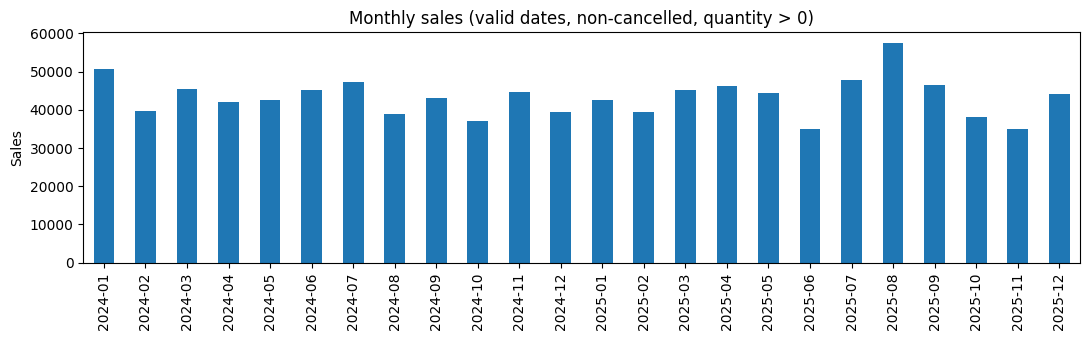

In [29]:
ax = monthly.plot(x='order_month', y='monthly_sales', kind='bar', figsize=(11, 3.5), legend=False,
                  title='Monthly sales (valid dates, non-cancelled, quantity > 0)')
ax.set_ylabel('Sales'); ax.set_xlabel('')
import matplotlib.pyplot as plt; plt.tight_layout(); plt.show()

**Query D — Monthly trend.** Sales cover 24 months, January 2024 to December 2025. Monthly sales vary between about $34.9k (June 2025) and $57.4k (August 2025) with no clear upward or downward trend; the data looks like random variation around roughly $43k a month. **Limitation:** 53 sales lines worth $10,901.34 (about 1%) are left out because their date is invalid, so monthly figures sum to about $1,037,437, not the full $1,048,338.

In [30]:
# Query E - order identifiers that appear on more than one row
print("In orders_raw:")
display(pd.read_sql_query("""
SELECT rows_per_order, COUNT(*) AS order_ids
FROM (SELECT order_id, COUNT(*) AS rows_per_order FROM orders_raw GROUP BY order_id)
GROUP BY rows_per_order;
""", conn))

display(pd.read_sql_query("""
SELECT order_id, COUNT(*) AS rows_per_order,
       COUNT(DISTINCT product_id) AS distinct_products,
       COUNT(DISTINCT IFNULL(customer_id,'') || quantity || order_date || status) AS distinct_versions
FROM orders_raw
GROUP BY order_id
HAVING COUNT(*) > 1
ORDER BY order_id
LIMIT 10;
""", conn))

print("In stg_orders (after de-duplication):")
display(pd.read_sql_query("""
SELECT COUNT(*) AS order_ids_with_multiple_rows
FROM (SELECT order_id FROM stg_orders GROUP BY order_id HAVING COUNT(*) > 1);
""", conn))

In orders_raw:


,rows_per_order,order_ids
0,1,4900
1,2,100


,order_id,rows_per_order,distinct_products,distinct_versions
0,O00021,2,1,1
1,O00022,2,1,1
2,O00154,2,1,1
3,O00184,2,1,1
4,O00301,2,1,1
5,O00392,2,1,1
6,O00418,2,1,1
7,O00441,2,1,1
8,O00530,2,1,1
9,O00562,2,1,1


In stg_orders (after de-duplication):


,order_ids_with_multiple_rows
0,0


**Query E — Repeated order IDs.** In the raw table, 100 order IDs appear twice, and each pair has the same product, customer, quantity, date and status. That is **not** normal for this table's grain (one row per order, one product), so it indicates a **load/duplication problem**, not multi-item orders. After de-duplication in `stg_orders`, no order ID appears more than once.

## 8. Reconcile your results with `orders_clean.csv`

`orders_clean.csv` is treated as a reference dataset. The comparison first aligns grain (one row per `order_id`), then checks key coverage, field values, and totals.

In [31]:
# --- 8.1 / 8.2  Row counts, columns, and business-key checks -----------------
print("Reference (orders_clean) rows:", len(orders_clean_df))
print("Raw (orders_raw) rows        :", len(orders_raw_df))
print("Reference columns:", orders_clean_df.columns.tolist())
print("Raw columns      :", orders_raw_df.columns.tolist())
print("Same column names:", orders_clean_df.columns.tolist() == orders_raw_df.columns.tolist())

print("\nMissing values by column (reference):")
display(orders_clean_df.isna().sum().rename("missing_count").to_frame())
print("Duplicate full rows (reference):", int(orders_clean_df.duplicated().sum()))

reference_key = "order_id"
print("Missing reference keys  :", int(orders_clean_df[reference_key].isna().sum()))
print("Duplicate reference keys:", int(orders_clean_df[reference_key].duplicated().sum()))
print("Distinct order_ids  reference:", orders_clean_df[reference_key].nunique(),
      "| raw:", orders_raw_df[reference_key].nunique())
print("\nGrain: both files have one row per order_id, with exactly one product_id and a quantity")
print("on each row (no order has several product lines), so the grain matches once raw duplicates are removed.")

Reference (orders_clean) rows: 5000
Raw (orders_raw) rows        : 5100
Reference columns: ['order_id', 'customer_id', 'product_id', 'quantity', 'order_date', 'status']
Raw columns      : ['order_id', 'customer_id', 'product_id', 'quantity', 'order_date', 'status']
Same column names: True

Missing values by column (reference):


,missing_count
order_id,0
customer_id,0
product_id,0
quantity,0
order_date,0
status,0


Duplicate full rows (reference): 0
Missing reference keys  : 0
Duplicate reference keys: 0
Distinct order_ids  reference: 5000 | raw: 5000

Grain: both files have one row per order_id, with exactly one product_id and a quantity
on each row (no order has several product lines), so the grain matches once raw duplicates are removed.


**8.1–8.2 Profile.** Same six column names in both files. The reference has 5,000 rows, no missing values, and no duplicate `order_id`, so `order_id` is a reliable business key. Raw has 5,100 rows but 5,000 distinct `order_id`. **Grain is the same** (one row per order with one product) once the raw duplicates are removed.

In [32]:
# --- 8.3 / 8.4  Key coverage: which order_ids are in only one dataset? ---------
# Use the staging view (one row per order_id) so the comparison is at the same grain.
transformed_df = pd.read_sql_query("""
SELECT order_id, customer_id, product_id, quantity, order_date, status, status_raw, unit_price
FROM stg_orders
""", conn)

coverage = transformed_df[["order_id"]].merge(
    orders_clean_df[["order_id"]], on="order_id", how="outer", indicator=True)
print("Key coverage (stg_orders vs orders_clean):")
display(coverage["_merge"].value_counts().to_frame("order_ids"))

# Raw rows that are surplus compared with the reference
print("Surplus raw rows vs reference:", len(orders_raw_df) - len(orders_clean_df),
      "-> equals duplicate rows removed:", int(orders_raw_df.duplicated(subset='order_id').sum()))

Key coverage (stg_orders vs orders_clean):


,order_ids
_merge,
both,5000
left_only,0
right_only,0


Surplus raw rows vs reference: 100 -> equals duplicate rows removed: 100


**8.3–8.4 Key coverage.** All 5,000 `order_id` values exist in both datasets (0 only in one side). The 100 extra raw rows are exactly the 100 duplicate rows, so the raw file contains no orders the reference lacks.

In [33]:
# --- 8.5  Field-by-field comparison on the shared key -------------------------
# Compare the RAW values (deduplicated, before our cleaning rules) with the reference,
# so every difference is a genuine disagreement between the two files.
raw_dedup = orders_raw_df.drop_duplicates(subset="order_id", keep="first")
cmp_ = raw_dedup.merge(orders_clean_df, on="order_id", suffixes=("_raw", "_ref"), how="inner")
print("Matched order_ids:", len(cmp_))

def differs(col):
    a, b = cmp_[f"{col}_raw"], cmp_[f"{col}_ref"]
    return ~((a == b) | (a.isna() & b.isna()))

diff_summary = pd.DataFrame({
    "column": ["customer_id", "product_id", "quantity", "order_date", "status"],
})
diff_summary["rows_that_differ"] = [int(differs(c).sum()) for c in diff_summary["column"]]
display(diff_summary)

any_diff = differs("customer_id") | differs("product_id") | differs("quantity") | differs("order_date") | differs("status")
print("Orders with at least one differing field:", int(any_diff.sum()), "of", len(cmp_))
print("Orders identical in both files         :", int((~any_diff).sum()))

# What do the differences look like?
print("\nStatus pairs that differ (raw -> reference):")
display(cmp_[differs("status")].groupby(["status_raw", "status_ref"]).size().rename("rows").reset_index())

print("Quantity: is the raw value just the reference with the sign flipped?")
qd = cmp_[differs("quantity")]
print("  rows differing:", len(qd), "| raw == -reference for all of them:", bool((qd.quantity_raw == -qd.quantity_ref).all()))

print("\nCustomer: raw is blank in every differing row?", bool(cmp_[differs("customer_id")].customer_id_raw.isna().all()))
print("Date    : raw value in every differing row ->", cmp_[differs("order_date")].order_date_raw.unique().tolist())

Matched order_ids: 5000


,column,rows_that_differ
0,customer_id,169
1,product_id,0
2,quantity,51
3,order_date,57
4,status,97


Orders with at least one differing field: 374 of 5000
Orders identical in both files         : 4626

Status pairs that differ (raw -> reference):


,status_raw,status_ref,rows
0,IN_TRANSIT!!,cancelled,5
1,IN_TRANSIT!!,delivered,71
2,IN_TRANSIT!!,pending,11
3,IN_TRANSIT!!,shipped,10


Quantity: is the raw value just the reference with the sign flipped?
  rows differing: 51 | raw == -reference for all of them: True

Customer: raw is blank in every differing row? True
Date    : raw value in every differing row -> ['not-a-date']


**8.5 Field comparison.** Matching on `order_id` (raw after removing duplicates vs. reference): `product_id` matches in all 5,000 orders; the differences are 169 `customer_id`, 51 `quantity`, 57 `order_date` and 97 `status` values. Together 374 orders differ in at least one field and 4,626 (92.5%) are identical. Every difference is traceable to one of the injected issues: customer blank in raw, quantity equal to the reference with its sign flipped, date `not-a-date`, and status `IN_TRANSIT!!`. The reference shows `IN_TRANSIT!!` orders were actually 71 delivered, 11 pending, 10 shipped and 5 cancelled, which supports mapping them to `unknown` rather than guessing.

In [34]:
# --- 8.5  Numeric comparison: line-level sales with a 0.01 tolerance -----------
prices = products_df.set_index("product_id")["price"]
cmp_["sales_raw"] = cmp_["quantity_raw"] * cmp_["product_id_raw"].map(prices)      # raw quantity as-is
cmp_["sales_ref"] = cmp_["quantity_ref"] * cmp_["product_id_ref"].map(prices)
cmp_["absolute_difference"] = (cmp_["sales_raw"] - cmp_["sales_ref"]).abs()

TOL = 0.01
bad = cmp_[cmp_["absolute_difference"] > TOL]
print(f"Rows where |raw sales - reference sales| > {TOL}:", len(bad))
display(bad.sort_values("absolute_difference", ascending=False)
          [["order_id", "product_id_raw", "quantity_raw", "quantity_ref", "sales_raw", "sales_ref", "absolute_difference"]].head(10))

# --- Total sales: only valid when both sides use the same definition ------------
# (a) Reference: every row, quantity * price      (b) Raw: after applying OUR rules
ref_total_all = round(cmp_["sales_ref"].sum(), 2)
raw_naive_with_dups = round((orders_raw_df["quantity"] * orders_raw_df["product_id"].map(prices)).sum(), 2)
raw_naive_dedup = round(cmp_["sales_raw"].sum(), 2)
stg_total_all_qty_abs = round((transformed_df["quantity"].abs() * transformed_df["unit_price"]).sum(), 2)

recon_bridge = pd.DataFrame([
    ("Raw file, naive (duplicates + negative quantities as-is)", raw_naive_with_dups),
    ("Raw file after removing duplicate order_ids",              raw_naive_dedup),
    ("Raw file after dedup AND treating negative qty as positive (|qty|)", stg_total_all_qty_abs),
    ("Reference orders_clean (all rows, qty x price)",           ref_total_all),
], columns=["definition", "total_sales_all_statuses"])
recon_bridge["difference_vs_reference"] = (recon_bridge["total_sales_all_statuses"] - ref_total_all).round(2)
display(recon_bridge)

Rows where |raw sales - reference sales| > 0.01: 51


,order_id,product_id_raw,quantity_raw,quantity_ref,sales_raw,sales_ref,absolute_difference
863,O02253,P009,-5,5,-649.95,649.95,1299.90
4937,O03643,P014,-4,4,-639.96,639.96,1279.92
851,O00899,P019,-5,5,-499.95,499.95,999.90
1987,O04599,P001,-5,5,-449.95,449.95,899.90
4707,O00889,P005,-2,2,-399.98,399.98,799.96
4907,O00256,P005,-2,2,-399.98,399.98,799.96
4290,O01465,P019,-4,4,-399.96,399.96,799.92
49,O00816,P001,-4,4,-359.96,359.96,719.92
3605,O01420,P018,-5,5,-349.95,349.95,699.90
4926,O04686,P011,-4,4,-319.96,319.96,639.92


,definition,total_sales_all_statuses,difference_vs_reference
0,"Raw file, naive (duplicates + negative quantit...",1113264.53,1131.8
1,Raw file after removing duplicate order_ids,1092521.43,-19611.3
2,Raw file after dedup AND treating negative qty...,1112132.73,0.0
3,"Reference orders_clean (all rows, qty x price)",1112132.73,0.0


In [35]:
# --- 8.6  Reference vs our staging view: sales by status ------------------------
ref_by_status = (orders_clean_df.merge(products_df[["product_id", "price"]], on="product_id")
                 .assign(sales=lambda d: d.quantity * d.price)
                 .groupby("status")["sales"].sum().round(2).rename("reference_sales"))
stg_by_status = pd.read_sql_query("""
SELECT status, ROUND(SUM(line_total), 2) AS stg_sales FROM stg_orders GROUP BY status
""", conn).set_index("status")["stg_sales"]
by_status = pd.concat([ref_by_status, stg_by_status], axis=1).fillna(0)
by_status["absolute_difference"] = (by_status["stg_sales"] - by_status["reference_sales"]).abs().round(2)
display(by_status)

# Save the reconciliation outputs into the database too
cmp_.drop(columns=["sales_raw", "sales_ref"]).assign(any_difference=any_diff.values)\
    .to_sql("recon_order_comparison", conn, if_exists="replace", index=False)
recon_bridge.to_sql("recon_totals_bridge", conn, if_exists="replace", index=False)
conn.commit()

,reference_sales,stg_sales,absolute_difference
status,,,
cancelled,55268.77,53988.96,1279.81
delivered,772327.95,751840.87,20487.08
pending,111237.87,106978.37,4259.50
shipped,173298.14,169858.64,3439.50
unknown,0.00,19660.24,19660.24


**8.5–8.6 Numeric comparison and explanation of differences**

Line-level sales (quantity × price) differ by more than the 0.01 tolerance in **51 orders**. These are the negative-quantity orders, and the absolute difference is exactly twice the true line value, because the sign is flipped. Orders with other kinds of difference (customer, date, status) have no effect on line sales.

**Difference 1 — Duplicates and negative quantities offset each other in the total.** The naive raw total ($1,113,264.53) looks close to the reference ($1,112,132.73), only $1,131.80 higher, which could be mistaken for good data. The close match is a coincidence of two errors in opposite directions: duplicates add $20,743.10, and negative quantities subtract $19,611.30. After removing duplicates the raw total is $19,611.30 *below* the reference, and after treating the negative quantities as positive it matches to the cent ($0.00 difference). A total-only check would have missed both issues, so reconciliation has to be done at order level.

**Difference 2 — Staging sales by status differ from the reference by design.** The staging view gives negative-quantity orders no `line_total` (so delivered, shipped, pending and cancelled sales are all lower than the reference), and `IN_TRANSIT!!` orders sit in their own `unknown` bucket ($19,660.24) that the reference splits across the four real statuses. These differences are expected consequences of the cleaning rules, not errors in the reference.

**Difference 3 — Data lost to missing keys.** 169 orders have no customer and 57 have no date in raw, but both fields are complete in the reference. The reference therefore appears to be the original, uncorrupted version of these orders, and the missing values cannot be recovered from the raw file alone.

**To make the two comparable** the raw side needs: de-duplicate on `order_id`; treat negative quantity as an error (or take the absolute value only if the business confirms they are sign errors); and map `IN_TRANSIT!!` to a real status via the source system. The comparison above shows these steps would bring raw to full agreement on key, product and (after the quantity fix) total sales.

## 9. Save your work

Save the notebook with **File → Save a copy in Drive** and download `retail_lab.db`. The database contains the three raw tables, the three staging views, and the extra tables `dq_results`, `recon_order_comparison` and `recon_totals_bridge`.

In [36]:
conn.commit()

# Final inventory of what is stored in the database
display(pd.read_sql_query("SELECT type, name FROM sqlite_master WHERE type IN ('table','view') ORDER BY type, name;", conn))

# Run this when you have finished using the database connection.
# conn.close()

try:
    from google.colab import files
    files.download('/content/retail_lab.db')
except ImportError:
    print("Not running in Colab - database saved at:", DB_PATH.resolve())

,type,name
0,table,customers
1,table,dq_results
2,table,orders_raw
3,table,products
4,table,recon_order_comparison
5,table,recon_totals_bridge
6,view,stg_customers
7,view,stg_orders
8,view,stg_products


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Findings summary

**Data quality.** The customer and product tables are clean (unique keys, no missing values, no orphan references from orders). `orders_raw` has 5,100 rows for only 5,000 orders and contains five kinds of problem: **100 exact duplicate rows, 173 missing customer IDs, 53 negative quantities, 58 invalid dates and 98 undefined status labels (`IN_TRANSIT!!`)**. All were handled in `stg_orders` by removing duplicates or setting the bad field to NULL / `unknown`, with no values guessed. There is no price or total column in the orders, so sales are calculated as quantity × product price.

**Analytical findings** (4,698 sales lines after removing cancelled and invalid-quantity rows):
- Total sales **$1,048,338.12**, average line (= order) value **$223.15**.
- **Smart Watch** is the top product (about $173k, 16.5% of sales); **Electronics** is 38.3% of sales.
- All 500 customers have at least one order (median 9); **$32.6k (3.1%) of sales** cannot be assigned to a customer.
- Monthly sales are stable at around $35k–$57k over Jan 2024 – Dec 2025 with no clear trend (peak Aug 2025, low Jun 2025); 1% of sales is excluded because of invalid dates.

**Reconciliation.** `orders_clean.csv` has the same grain and the same 5,000 `order_id` values as the de-duplicated raw file. 4,626 orders match exactly; the 374 that differ are explained by the injected issues (blank customer, bad date, sign-flipped quantity, `IN_TRANSIT!!` status). Naive totals appear to agree within $1.1k, but only because duplicates (+$20.7k) and negative quantities (−$19.6k) cancel; after fixing both, total sales match the reference exactly.

**Items needing follow-up:** confirm with the business that negative quantities are sign errors rather than returns; find the true status behind `IN_TRANSIT!!`; recover missing customer IDs and dates from the source system.

## Student checklist

- [x] Inspected all four CSV files.
- [x] Loaded three raw tables into SQLite.
- [x] Documented actual schemas and table grain.
- [x] Created and improved all three staging views using actual field names.
- [x] Ran data-quality checks and explained decisions.
- [x] Answered five business questions with SQL (A–E).
- [x] Compared results with `orders_clean.csv`.
- [ ] Saved the notebook and downloaded `retail_lab.db` (do this in Colab).
- [ ] Added name and pushed to GitHub per Step 10.